In [2]:
import numpy as np
import torch
import torch.nn as nn
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report

# Model definition from threat_detection 
"""
78 features, 256 neurons, 128 neurons, 64 neurons, 2 outputs
"""
class ThreatDetector(nn.Module):
    def __init__(self, input_dim):
        super(ThreatDetector, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),    # learns weights
            nn.BatchNorm1d(256),          # normalizes values between layers, stabilizes training
            nn.ReLU(),                    # activation function. non-linearity for model to learn complex patterns 
            nn.Dropout(0.3),              # turns of at 30% of neurons during training to prevent the model from memorizing instead of learning
            
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 2)    # Two(2) outputs - benign or attack
        )
    def forward(self, x):
        return self.network(x)

# Loading the saved model
device = torch.device("cpu")
model = ThreatDetector(input_dim=78)
model.load_state_dict(torch.load("../results/threat_detector.pth", map_location=device))
model.eval()

with open("../results/scaler.pkl", "rb") as f:
    scaler = pickle.load(f)

print("Model and scaler loaded successfuly")

Model and scaler loaded successfuly


## Reloading and Preparing the test data

In [3]:
import os
import pandas as pd

data_dir = "../data/MachineLearningCVE/"

dfs = []

for filename in os.listdir(data_dir):
    if filename.endswith(".csv"):
        temp = pd.read_csv(os.path.join(data_dir, filename), low_memory=False)
        temp.columns = temp.columns.str.strip()
        temp = temp.sample(frac=0.3, random_state=42)
        dfs.append(temp)

df_all = pd.concat(dfs, ignore_index=True)

# Clean
num_cols = df_all.select_dtypes(include=np.number).columns
for col in num_cols:
    df_all[col] = df_all[col].replace([np.inf, -np.inf], np.nan)
df_all.dropna(inplace=True)

# Labels and Features
df_all['binary_label'] = (df_all['Label'].str.strip() != 'BENIGN').astype(int)
X = df_all.drop(columns=['Label', 'binary_label']).values.astype(np.float32)
y = df_all['binary_label'].values

# Scaling using the same scaler from training
X_scaled = scaler.transform(X)

# Isolate only attack samples. These are the ones we are trying to fool
attack_mask = y == 1
X_attacks = X_scaled[attack_mask]
y_attacks = y[attack_mask]

print(f"Total attack samples: {X_attacks.shape[0]:,}")

Total attack samples: 166,928


## Model Accuracy

In [5]:
from torch.utils.data import DataLoader, TensorDataset

X_attack_tensor = torch.tensor(X_attacks, dtype=torch.float32)
y_attack_tensor = torch.tensor(y_attacks, dtype=torch.long)

loader = DataLoader(TensorDataset(X_attack_tensor, y_attack_tensor), batch_size=1024)

preds = []
with torch.no_grad():
    for X_batch, _ in loader:
        out = model(X_batch)
        preds.extend(out.argmax(1).numpy())

baseline_f1 = f1_score(y_attacks, preds)
baseline_acc = (np.array(preds) == y_attacks).mean()

print(f"Baseline accuracy on attacks: {baseline_acc:.1%}")
print(f"Baseline F1 on attacks: {baseline_f1:.4f}")

"""
Results:
    Baseline accuracy on attacks: 99.8%
    Baseline F1 on attacks: 0.9988

This means the model catches nearly every attach when the data is clean (99.8%). This is before number
"""

Baseline accuracy on attacks: 99.8%
Baseline F1 on attacks: 0.9988


## FGSM Attack

In [6]:
"""
Fast Gradient Sign Method (FGSM)
epsilon controls how string the attack
higher = more perturbation
"""
def fgsm_attack(model, X, epsilon):
    X_tensor = torch.tensor(X, dtype=torch.float32, requires_grad=True)

    output = model(X_tensor)    # Forward pass

    target = torch.zeros(len(X), dtype=torch.long)     # We want the model to think these are BENIGN (class 0)

    # Calculate loss
    loss = nn.CrossEntropyLoss()(output, target)

    loss.backward()            # Backward pass - compute gradients which tells how each input feature affects loss

    # Pertrub input in the direction that maximizes loss
    perturbation = epsilon * X_tensor.grad.sign()          # the direction to nudge it
    X_adversarial = X_tensor + perturbation

    return X_adversarial.detach().numpy()

print("FGSM function defined")

FGSM function defined


## Running FGSM with different epsilon values 

In [7]:
epsilons = [0.01, 0.05, 0.1, 0.2, 0.3]
results = []

model.eval()

for eps in epsilons:
    X_adv = fgsm_attack(model, X_attacks, eps)          # Generate adversarial examples

    # Run adversarial examples through the model
    adv_tensor = torch.tensor(X_adv, dtype=torch.float32)
    loader_adv = DataLoader(TensorDataset(adv_tensor), batch_size=1024)

    preds_adv = []
    with torch.no_grad():
        for (X_batch,) in loader_adv:
            out = model(X_batch)
            preds_adv.extend(out.argmax(1).numpy())

    acc = (np.array(preds_adv) == y_attacks).mean()
    results.append((eps, acc))
    print(f"Epsilon: {eps:.2f} | Attack accuracy: {acc:.1%}")

Epsilon: 0.01 | Attack accuracy: 99.8%
Epsilon: 0.05 | Attack accuracy: 99.8%
Epsilon: 0.10 | Attack accuracy: 98.6%
Epsilon: 0.20 | Attack accuracy: 94.8%
Epsilon: 0.30 | Attack accuracy: 94.6%


## PGD Attack(stronger, iterative)

In [14]:
"""
PGD Attack - iterative version of FGSM
epsilon = total allowed perturbation budget
alpha = step size per iteration
num_steps = how many iterations

PGD with margin loss - works better when model is higly confident. 
Instead of CrossEntropy, we directly maximize (logit_benign - logit_attack)
It directly pushes the model toward predicting benign
"""
def pgd_attack(model, X, epsilon, alpha=0.01, num_steps=40):
    X_tensor = torch.tensor(X, dtype=torch.float32)
    X_adv = X_tensor.clone()

    for step in range(num_steps):
        X_adv.requires_grad_(True)

        output = model(X_adv)
        # Margin loss: maximize gap between benign logit and attack logit
        # output[:, 0] = benign score, output[:, 1] = attack score
        # target = torch.zeros(len(X), dtype=torch.long)    # trick into predicting
        #loss = nn.CrossEntropyLoss()(output, target)

        loss = (output[:, 0] - output[:, 1]).mean()
        loss.backward()

        # Small step in gradient direction
        X_adv = X_adv + alpha * X_adv.grad.sign()

        # Project back within epsilon ball - keeps perturbation bounded
        X_adv = torch.clamp(X_adv, X_tensor - epsilon, X_tensor + epsilon)
        X_adv = X_adv.detach()

    return X_adv.numpy()

print("PGD function defined")

PGD function defined


## Running PGD

In [15]:
pgd_results = []

for eps in epsilons:
    print(f"Running PGD at epsilon={eps:.2f}...", end=" ")

    X_adv = pgd_attack(model, X_attacks, epsilon=eps)

    adv_tensor = torch.tensor(X_adv, dtype=torch.float32)
    loader_adv = DataLoader(TensorDataset(adv_tensor), batch_size=1024)

    preds_adv = []
    with torch.no_grad():
        for (X_batch,) in loader_adv:
            out = model(X_batch)
            preds_adv.extend(out.argmax(1).numpy())
    acc = (np.array(preds_adv) == y_attacks).mean()
    pgd_results.append((eps, acc))
    print(f"Attack Accuracy: {acc:.1%}")
        

Running PGD at epsilon=0.01... Attack Accuracy: 97.6%
Running PGD at epsilon=0.05... Attack Accuracy: 65.5%
Running PGD at epsilon=0.10... Attack Accuracy: 40.9%
Running PGD at epsilon=0.20... Attack Accuracy: 32.1%
Running PGD at epsilon=0.30... Attack Accuracy: 21.9%


## FGSM vs PGD comparison

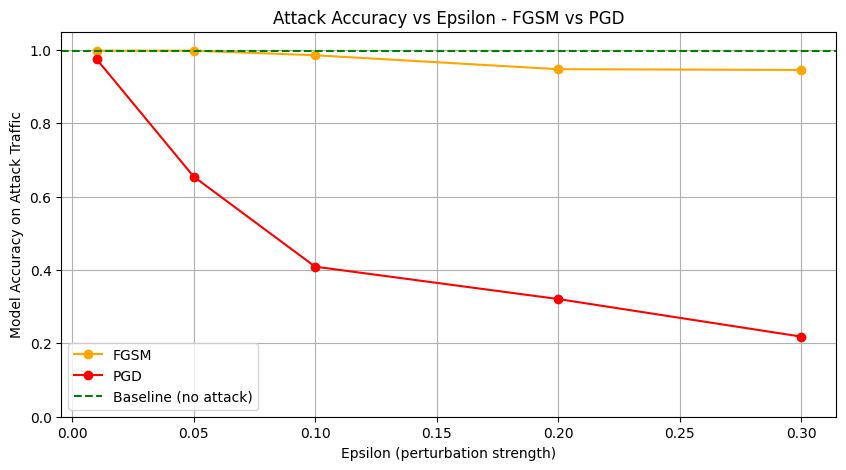


Summary:
Baseline: 99.8%
FGSM (eps=0.30): 94.6%
PGD (eps=0.30): 21.9%


In [18]:
fgsm_accs = []
for epsilon, acc in results:
    fgsm_accs.append(acc)
pgd_accs = []
for epsilon, acc in pgd_results:
    pgd_accs.append(acc)

plt.figure(figsize=(10, 5))
plt.plot(epsilons, fgsm_accs, marker='o', label='FGSM', color='orange')
plt.plot(epsilons, pgd_accs, marker='o', label='PGD', color='red')
plt.axhline(y=0.998, color='green', linestyle='--', label='Baseline (no attack)')

plt.title("Attack Accuracy vs Epsilon - FGSM vs PGD")
plt.xlabel("Epsilon (perturbation strength)")
plt.ylabel("Model Accuracy on Attack Traffic")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)

os.makedirs("../results", exist_ok=True)
plt.savefig("../results/attack_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nSummary:")
print(f"Baseline: 99.8%")
print(f"FGSM (eps=0.30): {fgsm_accs[-1]:.1%}")
print(f"PGD (eps=0.30): {pgd_accs[-1]:.1%}")